# 10 · El avance temprano, ¿causa la mora o la anuncia?

**Pregunta de decisión.** Las cuentas que hacen avances de efectivo en los primeros meses caen más en mora. La pregunta que decide la política es *por qué*:

| Si el avance… | Mecanismo | Acción | Dueño |
|---|---|---|---|
| **anuncia** la mora | quien está en estrés pide efectivo (selección) | alerta temprana, gestión de cupo, contacto preventivo | Seguimiento / Cobranza |
| **causa** la mora | más exposición y apalancamiento empujan el impago | restringir o escalonar el cupo de avance en los primeros N días | Producto / Riesgo |

Las dos cosas pueden ser ciertas a la vez; lo que importa es **cuánto** de la asociación es causal, porque eso fija cuánta mora evita restringir el avance y cuánto ingreso por comisiones se sacrifica.

**Estrategia de identificación**, de menor a mayor credibilidad:

1. **Landmark en MOB 1 con ajuste por estratos:** compara cuentas en riesgo al cierre de MOB 1 con y sin avance. Controla lo observado, pero no el estrés no observado.
2. **Diferencias en diferencias sobre un cambio de política ya ocurrido:** si el cupo de avance cambió para un grupo y no para otro, la comparación antes/después aísla el efecto de la política bajo tendencias paralelas.
3. **Regresión discontinua en un umbral que cambia el tratamiento entre aprobados:** por ejemplo, un cupo mayor desde cierto score. **No** sirve en el umbral de aprobación para medir mora: debajo del corte no hay desempeño.
4. **Prueba controlada** (notebook 11): la evidencia definitiva.

> **Estado:** plantilla con demostración aislada. La simulación planta un efecto causal del avance **y** una selección por estrés no observado, para mostrar qué recupera cada método.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
BASE = Path.cwd()
if not (BASE / 'decision_core.py').exists():
    root = next(p for p in [BASE, *BASE.parents] if (p / '03-financial-risk').is_dir())
    BASE = root / '03-financial-risk/01-credit-risk/credit-vintage-snapshot-lab'
sys.path.insert(0, str(BASE))
import decision_core as dc
from vintage_core import build_vintage, summarize_vintage
from demo_inputs import demo_cartera
plt.rcParams.update({'figure.figsize': (10, 4.6), 'font.size': 10.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18,
                     'axes.axisbelow': True, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left'})
AZUL, OCRE, GRIS, ROJO = '#25658c', '#d4854a', '#9aa5b1', '#b5443b'
SIM = 'Datos simulados · no representa una cartera'
pd.options.display.float_format = '{:,.4f}'.format

def leer(nombre):
    """Lee una plantilla local; las del repositorio solo tienen encabezados."""
    return pd.read_csv(BASE / nombre, encoding='utf-8-sig')

def pct(x, d=1):
    return 'n/d' if pd.isna(x) else f'{100 * x:.{d}f} %'

def cop(x):
    return 'n/d' if pd.isna(x) else f'COP {x / 1e6:,.1f} M'

### Con datos de la entidad

In [2]:
mob1 = leer('plantilla_modelado_mob1.csv'); politicas = leer('plantilla_politicas.csv'); avances = leer('plantilla_avances_tarjeta.csv')
print(f'Tabla MOB 1: {len(mob1):,} | versiones de política: {len(politicas):,} | avances: {len(avances):,}')
if mob1.empty or avances.empty:
    print('PENDIENTE: tabla de cuentas en riesgo al cierre de MOB 1 (notebooks 04 y 05) con avances disponibles a esa fecha.')
if politicas.empty:
    print('PENDIENTE: historial de versiones de política con fecha de vigencia, segmento afectado y regla (cupo de avance, cupo, corte).')

Tabla MOB 1: 0 | versiones de política: 0 | avances: 0
PENDIENTE: tabla de cuentas en riesgo al cierre de MOB 1 (notebooks 04 y 05) con avances disponibles a esa fecha.
PENDIENTE: historial de versiones de política con fecha de vigencia, segmento afectado y regla (cupo de avance, cupo, corte).


## 1 · Lo que se observa: mora según el momento del primer avance

In [3]:
# Cartera ficticia con mecanismos plantados (ver demo_inputs.demo_cartera).
DEMO = demo_cartera()
V = DEMO['verdad']
cuentas, solicitudes, panel_demo, macro_demo = DEMO['cuentas'], DEMO['solicitudes'], DEMO['panel'], DEMO['macro']
cuentas['banda_score'] = pd.cut(cuentas.score_buro, [0, 620, 660, 700, 2000], right=False,
                                labels=['<620', '620–659', '660–699', '700+'])
print(f'Solicitudes simuladas: {len(solicitudes):,} | aprobadas: {len(cuentas):,} | '
      f'EVER30@MOB3 simulado: {pct(cuentas.evento_temprano.mean())}')

Solicitudes simuladas: 30,000 | aprobadas: 20,379 | EVER30@MOB3 simulado: 10.5 %


,n,eventos,ever30,ic_bajo,ic_alto
momento_avance,,,,,
MOB 1,3745,703,0.1877,0.1755,0.2005
MOB 2,2761,323,0.1170,0.1055,0.1295
MOB 3,1973,93,0.0471,0.0386,0.0574
sin avance,11900,1024,0.0861,0.0811,0.0912


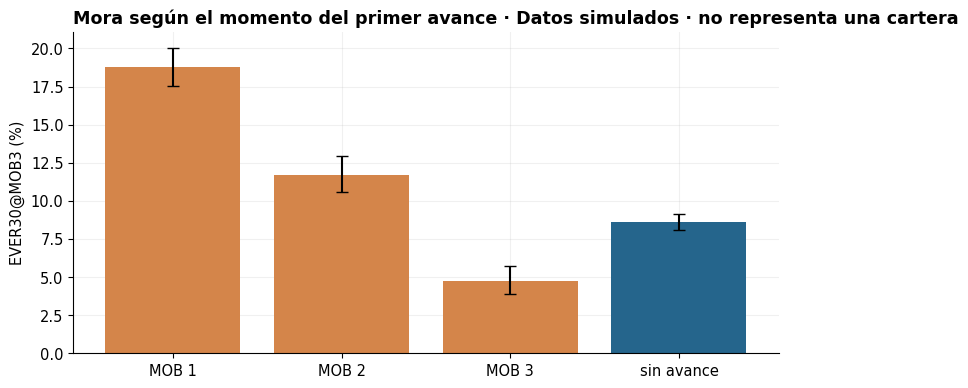

Advertencia: un avance en MOB 3 puede ocurrir después del evento de mora; esta tabla no establece orden temporal.


In [4]:
c = cuentas.copy()
c['momento_avance'] = c.primer_mob_avance.astype('float').map({1: 'MOB 1', 2: 'MOB 2', 3: 'MOB 3'}).fillna('sin avance')
t = c.groupby('momento_avance').agg(n=('evento_temprano', 'size'), eventos=('evento_temprano', 'sum')).reindex(['MOB 1', 'MOB 2', 'MOB 3', 'sin avance'])
t['ever30'] = t.eventos / t.n
t['ic_bajo'], t['ic_alto'] = dc.wilson_interval(t.eventos, t.n)
display(t)
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(t.index, 100 * t.ever30, color=[OCRE, OCRE, OCRE, AZUL], yerr=[100 * (t.ever30 - t.ic_bajo), 100 * (t.ic_alto - t.ever30)], capsize=4)
ax.set(ylabel='EVER30@MOB3 (%)', title=f'Mora según el momento del primer avance · {SIM}'); plt.tight_layout(); plt.show()
print('Advertencia: un avance en MOB 3 puede ocurrir después del evento de mora; esta tabla no establece orden temporal.')

## 2 · Landmark en MOB 1 con Mantel-Haenszel

Población: cuentas **sin** evento hasta MOB 1. Exposición: avance en MOB 1. Resultado: primer DPD > 30 en MOB 2–3. Así el avance precede al resultado y se evita el sesgo de tiempo inmortal. El riesgo relativo de Mantel-Haenszel ajusta por estrategia, banda de score, tipo de persona y departamento:

$$\widehat{RR}_{MH}=\frac{\sum_k a_k n_{0k}/N_k}{\sum_k c_k n_{1k}/N_k},$$

con IC de Greenland-Robins. Ajustar por lo observado **no** corrige la selección por estrés no observado.

In [5]:
pev, pav = c.primer_mob_evento.astype('float'), c.primer_mob_avance.astype('float')
lm = c[pev.isna() | (pev > 1)].copy()
lm['avance_mob1'] = (pav[lm.index] == 1).astype(int)
lm['evento_mob2_3'] = (pev[lm.index] >= 2).astype(int)
mh = dc.mantel_haenszel(lm, exposure_col='avance_mob1', outcome_col='evento_mob2_3',
                        strata_cols=['estrategia_originacion', 'banda_score', 'tipo_persona', 'departamento'])
display(pd.Series(mh).to_frame('landmark MOB 1'))
print(f"RR causal plantado entre quienes hicieron avance en MOB 1: {V['rr_causal_avance_mob1']:.2f}")
assert mh['rr_mh_ic_bajo'] > V['rr_causal_avance_mob1'], 'En la simulación el ajuste por observables no elimina la selección'
display(Markdown(f"**Lectura (simulada).** Entre cuentas al día en MOB 1, quienes hicieron avance tienen {mh['rr_crudo']:.2f} veces el riesgo "
                 f"en MOB 2–3; ajustado por estratos observados, {mh['rr_mh']:.2f} (IC {mh['rr_mh_ic_bajo']:.2f}–{mh['rr_mh_ic_alto']:.2f}). "
                 f"El efecto causal plantado es {V['rr_causal_avance_mob1']:.2f}: **el IC entero queda por encima**. La diferencia es selección "
                 "por estrés no observado, que un ajuste por variables de originación no puede quitar. Como **señal** de alerta el avance "
                 "sirve; como **estimación del efecto** de restringirlo, el landmark lo exagera."))

,landmark MOB 1
riesgo_expuestos,0.1634
riesgo_no_expuestos,0.0691
rr_crudo,2.3639
rd_crudo,0.0943
rr_mh,2.0875
rr_mh_ic_bajo,1.8983
rr_mh_ic_alto,2.2955
rd_mh,0.0828
estratos_usados,95.0000


RR causal plantado entre quienes hicieron avance en MOB 1: 1.60


**Lectura (simulada).** Entre cuentas al día en MOB 1, quienes hicieron avance tienen 2.36 veces el riesgo en MOB 2–3; ajustado por estratos observados, 2.09 (IC 1.90–2.30). El efecto causal plantado es 1.60: **el IC entero queda por encima**. La diferencia es selección por estrés no observado, que un ajuste por variables de originación no puede quitar. Como **señal** de alerta el avance sirve; como **estimación del efecto** de restringirlo, el landmark lo exagera.

## 3 · Diferencias en diferencias sobre la política P-AV-02

Desde la cohorte 2024-07, la política P-AV-02 bajó el cupo de avance de TPV del 30 % al 10 % del cupo; Experian no cambió. Con $y$ = EVER30@MOB3:

$$y_i=\alpha+\beta\,\text{TPV}_i+\gamma\,\text{post}_i+\delta\,(\text{TPV}_i\times\text{post}_i)+\varepsilon_i,$$

$\delta$ es el efecto de la política sobre TPV (intención de tratar), bajo **tendencias paralelas**: sin la política, la brecha TPV − Experian habría seguido igual. Se revisa con la brecha por cohorte antes del cambio. Errores agrupados por cohorte; con 12 cohortes, el IC es aproximado. La **primera etapa** (efecto sobre la tasa de avance) y el cociente de Wald dan el efecto **por avance evitado**.

,efecto,error_estandar,ic_bajo,ic_alto,p_valor,clusters,n
ITT sobre EVER30@MOB3,-0.0091,0.0104,-0.0296,0.0113,0.3815,12.0000,"20,379.0000"
primera etapa: avance en MOB 1,-0.1390,0.0098,-0.1581,-0.1199,0.0000,12.0000,"20,379.0000"


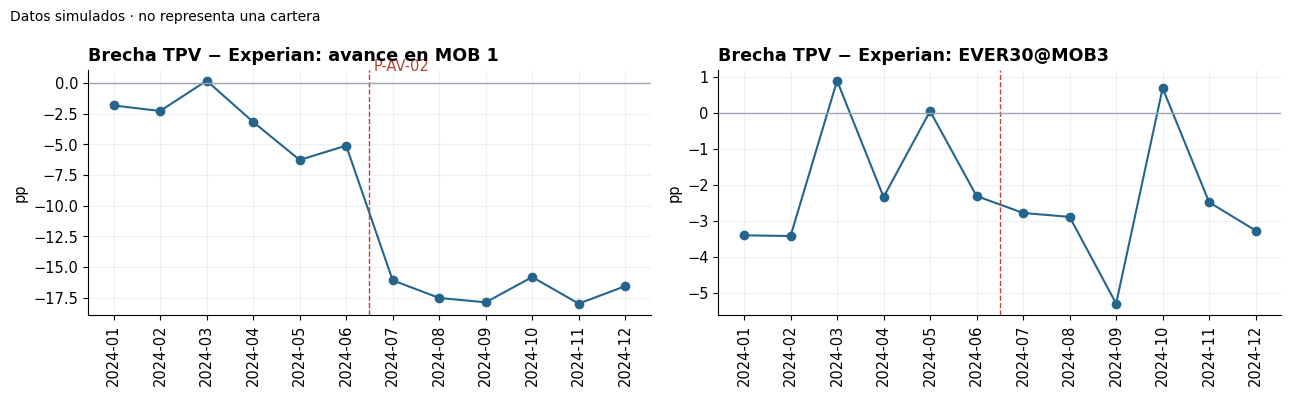

Tendencia de la brecha antes de P-AV-02: +0.36 pp por cohorte (p = 0.47, 6 cohortes)


**Lectura (simulada).** P-AV-02 redujo la tasa de avance en MOB 1 de TPV en 13.9 pp (primera etapa clara). Su efecto sobre el EVER30@MOB3 es -0.91 pp (IC -2.96 a +1.13; efecto plantado -0.88). El IC incluye cero: **la política probablemente funciona, pero con este volumen no se puede demostrar**. Por cada avance en MOB 1 evitado, la mora baja unos 6.6 pp (cociente de Wald). Antes del cambio, la brecha por cohorte no muestra tendencia significativa (p = 0.47), aunque con 6 cohortes la prueba tiene poca potencia. El tamaño necesario para una conclusión firme sale del notebook 11.

In [6]:
c['tpv'] = (c.estrategia_originacion == 'TPV').astype(int)
c['post'] = (c.corte_origen >= '2024-07').astype(int)
c['avance_mob1'] = (c.primer_mob_avance.astype('float') == 1).astype(int)
did = dc.did_estimate(c, outcome_col='evento_temprano', treated_col='tpv', post_col='post', cluster_col='corte_origen')
fs = dc.did_estimate(c, outcome_col='avance_mob1', treated_col='tpv', post_col='post', cluster_col='corte_origen')
wald = did['efecto'] / fs['efecto']
display(pd.DataFrame({'ITT sobre EVER30@MOB3': did, 'primera etapa: avance en MOB 1': fs}).T)
brecha = dc.did_by_cohort(c, outcome_col='evento_temprano', treated_col='tpv', cohort_col='corte_origen')
brecha_av = dc.did_by_cohort(c, outcome_col='avance_mob1', treated_col='tpv', cohort_col='corte_origen')

fig, axs = plt.subplots(1, 2, figsize=(13, 4))
for ax, b, tit in [(axs[0], brecha_av, 'Brecha TPV − Experian: avance en MOB 1'), (axs[1], brecha, 'Brecha TPV − Experian: EVER30@MOB3')]:
    ax.plot(b.corte_origen, 100 * b.brecha, marker='o', color=AZUL); ax.axvline(5.5, color=ROJO, ls='--', lw=1)
    ax.axhline(0, color=GRIS, lw=1); ax.set(title=tit, ylabel='pp'); ax.tick_params(axis='x', rotation=90)
axs[0].text(5.6, axs[0].get_ylim()[1] * .9, 'P-AV-02', color=ROJO)
fig.suptitle(SIM, x=.01, ha='left', fontsize=10); plt.tight_layout(); plt.show()

from scipy import stats as st
pre = brecha[brecha.corte_origen < '2024-07'].reset_index(drop=True)
pend = st.linregress(np.arange(len(pre)), pre.brecha)
print(f'Tendencia de la brecha antes de P-AV-02: {100 * pend.slope:+.2f} pp por cohorte (p = {pend.pvalue:.2f}, {len(pre)} cohortes)')
assert did['ic_bajo'] <= V['itt_politica_avance'] <= did['ic_alto'], 'El IC del DiD no cubre el efecto plantado'
assert fs['ic_alto'] < 0, 'La política reduce el avance'
sig = did['ic_alto'] < 0
display(Markdown(f"**Lectura (simulada).** P-AV-02 redujo la tasa de avance en MOB 1 de TPV en {100 * -fs['efecto']:.1f} pp (primera etapa clara). "
                 f"Su efecto sobre el EVER30@MOB3 es {100 * did['efecto']:+.2f} pp (IC {100 * did['ic_bajo']:+.2f} a {100 * did['ic_alto']:+.2f}; "
                 f"efecto plantado {100 * V['itt_politica_avance']:+.2f}). " + ("El efecto es significativo. " if sig else
                 "El IC incluye cero: **la política probablemente funciona, pero con este volumen no se puede demostrar**. ") +
                 f"Por cada avance en MOB 1 evitado, la mora baja unos {100 * wald:.1f} pp (cociente de Wald). Antes del cambio, la brecha por cohorte "
                 + (f"no muestra tendencia significativa (p = {pend.pvalue:.2f}), aunque con {len(pre)} cohortes la prueba tiene poca potencia. "
                    if pend.pvalue > .10 else f"muestra una tendencia (p = {pend.pvalue:.2f}): el supuesto de tendencias paralelas es dudoso. ")
                 + "El tamaño necesario para una conclusión firme sale del notebook 11."))

## 4 · Regresión discontinua en el umbral de cupo alto

Entre aprobados, el cupo se duplica desde score 700. Las cuentas a ambos lados del umbral son comparables, por lo que el salto en la mora mide el efecto **local** del cupo alto. Se estima con regresión lineal local y kernel triangular, y se reporta la sensibilidad al ancho de banda. Requisitos: que el score no se pueda manipular alrededor del umbral (revisar la densidad) y que nada más cambie en 700.

,ancho_banda,salto,error_estandar,ic_bajo,ic_alto,n_izquierda,n_derecha
0,30,0.0106,0.0145,-0.0179,0.0390,3537,2393
1,40,0.0112,0.0126,-0.0135,0.0360,4999,2926
2,60,0.0143,0.0106,-0.0065,0.0351,7990,3682
3,80,0.0159,0.0095,-0.0026,0.0344,11133,4121


Primera etapa: salto en la probabilidad de cupo alto = 1.00 (RD nítido)


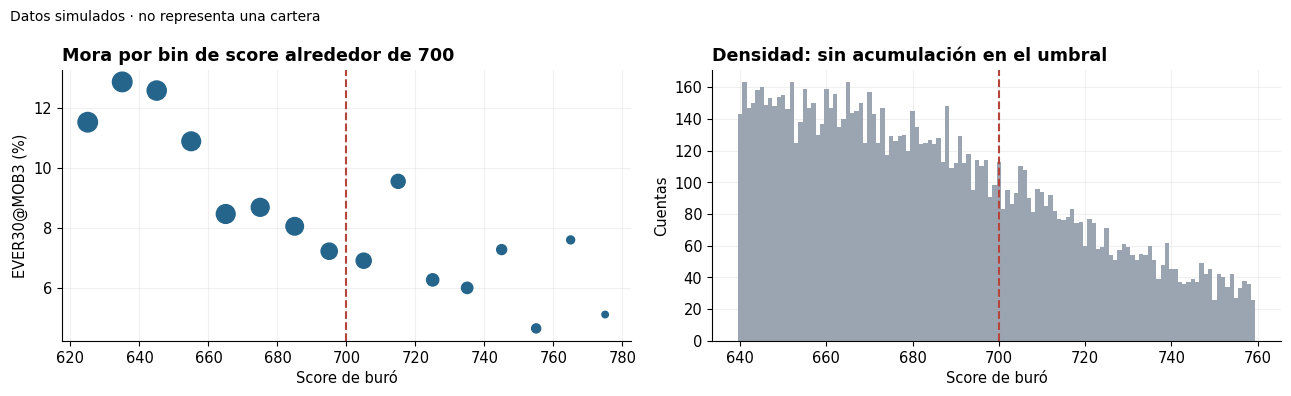

**Lectura (simulada).** Duplicar el cupo en el umbral 700 sube el EVER30@MOB3 en +1.12 pp (IC -1.35 a +3.60; plantado +1.78). La estimación es estable entre anchos de banda, pero imprecisa. Es un efecto local: no se extrapola a scores lejos de 700.

In [7]:
filas = []
for bw in (30, 40, 60, 80):
    filas.append({'ancho_banda': bw} | dc.rd_local_linear(c, running_col='score_buro', outcome_col='evento_temprano', cutoff=700, bandwidth=bw))
rd = pd.DataFrame(filas); display(rd)
fs_rd = dc.rd_local_linear(c, running_col='score_buro', outcome_col='cupo_alto', cutoff=700, bandwidth=40)
print(f"Primera etapa: salto en la probabilidad de cupo alto = {fs_rd['salto']:.2f} (RD nítido)")

ventana = c[(c.score_buro >= 620) & (c.score_buro < 780)].copy()
ventana['bin'] = (ventana.score_buro // 10) * 10
binned = ventana.groupby('bin').agg(ever=('evento_temprano', 'mean'), n=('evento_temprano', 'size')).reset_index()
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].scatter(binned.bin + 5, 100 * binned.ever, s=binned.n / 8, color=AZUL); axs[0].axvline(700, color=ROJO, ls='--')
axs[0].set(xlabel='Score de buró', ylabel='EVER30@MOB3 (%)', title='Mora por bin de score alrededor de 700')
dens = c[(c.score_buro >= 640) & (c.score_buro < 760)].score_buro.value_counts().sort_index()
axs[1].bar(dens.index, dens.values, color=GRIS, width=1); axs[1].axvline(700, color=ROJO, ls='--')
axs[1].set(xlabel='Score de buró', ylabel='Cuentas', title='Densidad: sin acumulación en el umbral')
fig.suptitle(SIM, x=.01, ha='left', fontsize=10); plt.tight_layout(); plt.show()
r40 = rd.set_index('ancho_banda').loc[40]
assert r40.ic_bajo <= V['efecto_local_cupo_alto'] <= r40.ic_alto, 'El IC del RD no cubre el efecto plantado'
display(Markdown(f"**Lectura (simulada).** Duplicar el cupo en el umbral 700 sube el EVER30@MOB3 en {100 * r40.salto:+.2f} pp "
                 f"(IC {100 * r40.ic_bajo:+.2f} a {100 * r40.ic_alto:+.2f}; plantado {100 * V['efecto_local_cupo_alto']:+.2f}). La estimación es "
                 "estable entre anchos de banda, pero imprecisa. Es un efecto local: no se extrapola a scores lejos de 700."))

## Síntesis para la decisión

| Evidencia | Qué estima | Uso |
|---|---|---|
| Landmark + MH | asociación ajustada por observables | **señal**: regla de alerta en la semana 1–4 (avance + otras señales), medida por lift y precisión según la capacidad de gestión |
| DiD sobre P-AV-02 | efecto de la política vigente (ITT) y por avance evitado (Wald) | **causa**: cuánto evita restringir el cupo de avance y cuánto cuesta en comisiones |
| RD en cupo 700 | efecto local del cupo sobre la mora | gestión de cupo inicial y de los aumentos de cupo |
| Prueba controlada | efecto causal con potencia diseñada | confirmación antes de generalizar (notebook 11) |

**Límites.** El DiD depende de tendencias paralelas y de que nada más cambiara para TPV en 2024-07. El RD es local. El landmark no separa causa y señal. Todo análisis de avances exige la fecha de disponibilidad del avance: un avance registrado después de la decisión no puede alimentar una alerta en ese momento.